# Part 1: Analyzing Best-Seller Trends Across Product Categories


**Objective**: Understand the relationship between product categories and their best-seller status.


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association



%matplotlib inline

In [2]:
csv_path = "amz_uk_price_prediction_dataset.csv"
df_amazon = pd.read_csv(csv_path)

In [3]:
df_amazon.shape

(2443651, 9)

In [4]:
df_amazon.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


## 1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


In [5]:
df_amazon['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [7]:
df_amazon['isBestSeller'].value_counts()

isBestSeller
False    2435671
True        7980
Name: count, dtype: int64

In [8]:
crosstab_result = pd.crosstab(df_amazon['category'], df_amazon['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


## 2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [9]:
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

In [10]:
chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [13]:
association(crosstab_result, method="cramer")

0.1222829439760564

## 3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

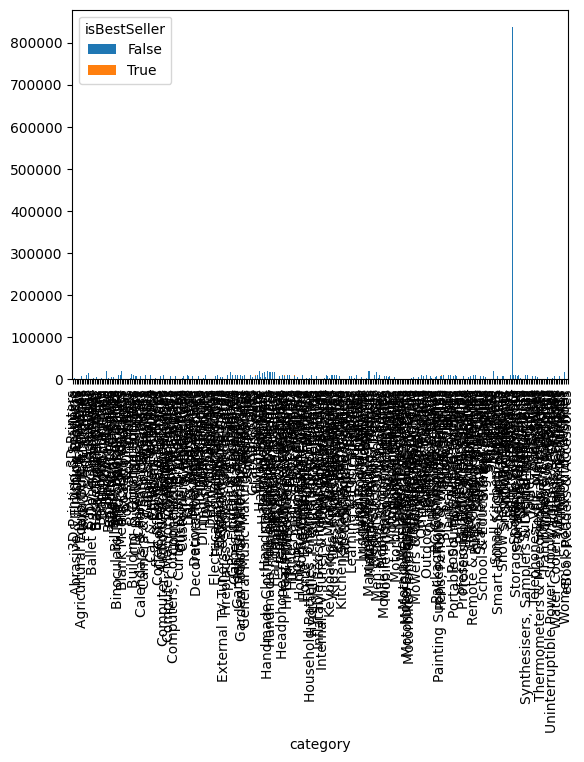

In [14]:
crosstab_result.plot(kind="bar", stacked=True)

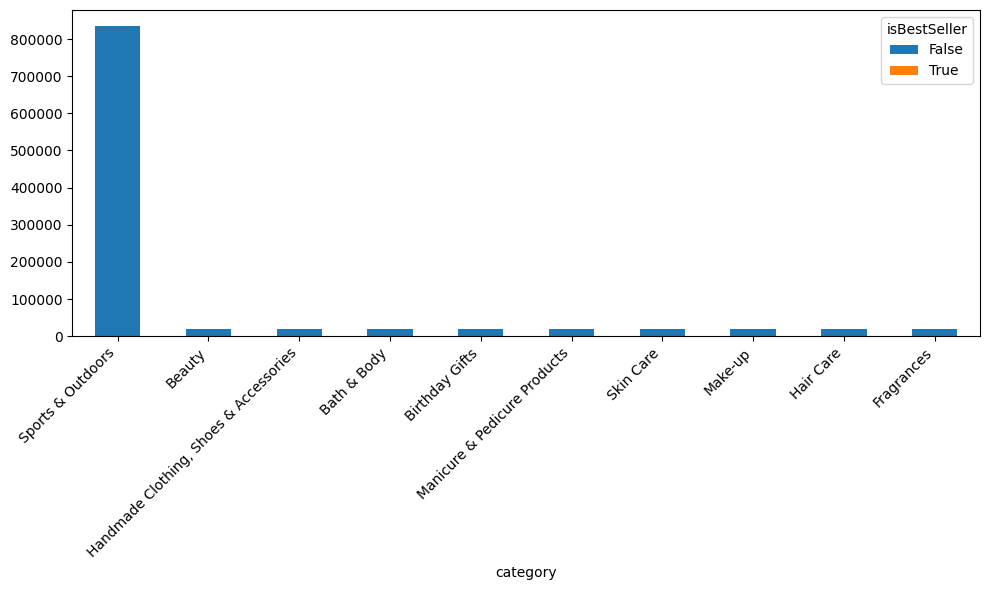

In [15]:
top10 = crosstab_result.loc[
    crosstab_result.sum(axis=1).nlargest(10).index
]

top10.plot(kind="bar", stacked=True, figsize=(10, 6))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

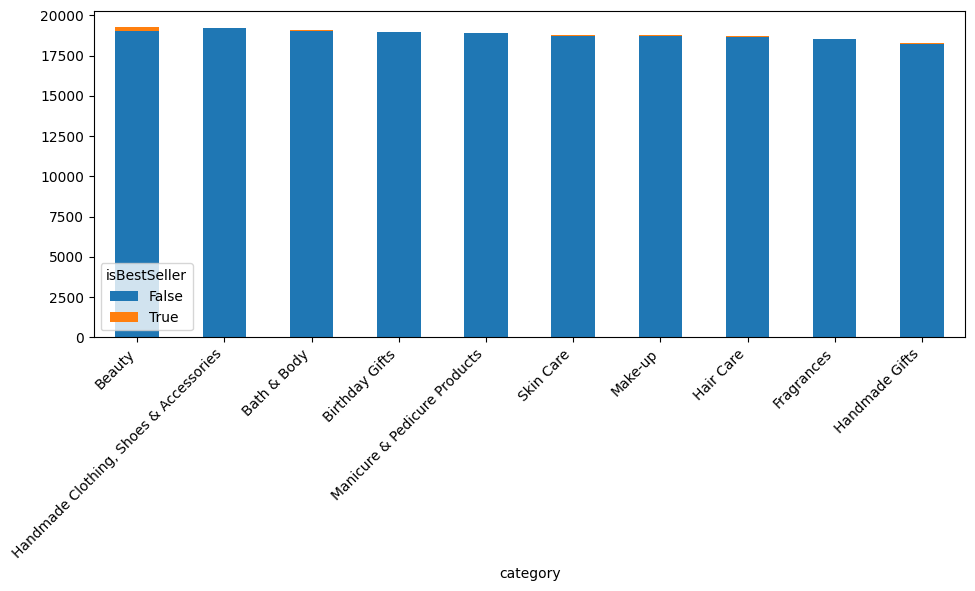

In [16]:
top10 = crosstab_result.loc[
    crosstab_result.sum(axis=1)
                   .sort_values(ascending=False)
                   .iloc[1:11]      # Skip the first (largest) category
                   .index
]

top10.plot(kind="bar", stacked=True, figsize=(10, 6))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.


## 0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [17]:
Q1 = df_amazon['price'].quantile(0.25)
Q3 = df_amazon['price'].quantile(0.75)
IQR = Q3 - Q1

In [18]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [19]:
df_amazon_no_outliers = df_amazon[
    (df_amazon['price'] >= lower_bound) &
    (df_amazon['price'] <= upper_bound)
]

In [20]:
print(f"Original rows: {len(df_amazon)}")
print(f"Rows after removing outliers: {len(df_amazon_no_outliers)}")
print(f"Outliers removed: {len(df_amazon) - len(df_amazon_no_outliers)}")

Original rows: 2443651
Rows after removing outliers: 2115963
Outliers removed: 327688


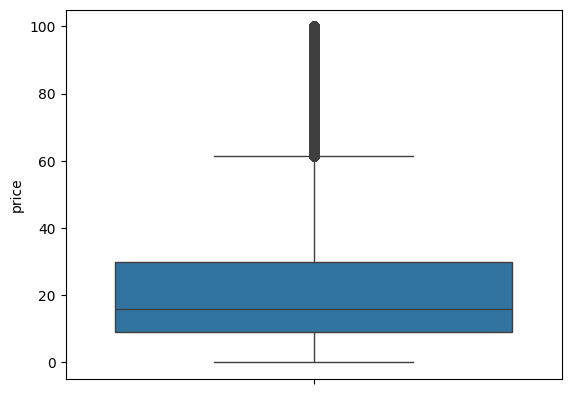

In [21]:
sns.boxplot(df_amazon_no_outliers['price'])
plt.show()

## 1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [ ]:
sns.violinplot(data=df_amazon_no_outliers, x='MSZoning', y='SalePrice', palette="coolwarm")

In [22]:
# Get the 20 most frequent categories
top20_categories = df_amazon_no_outliers['category'].value_counts().head(20).index

In [23]:
# Filter the DataFrame
df_top20 = df_amazon_no_outliers[df_amazon_no_outliers['category'].isin(top20_categories)]


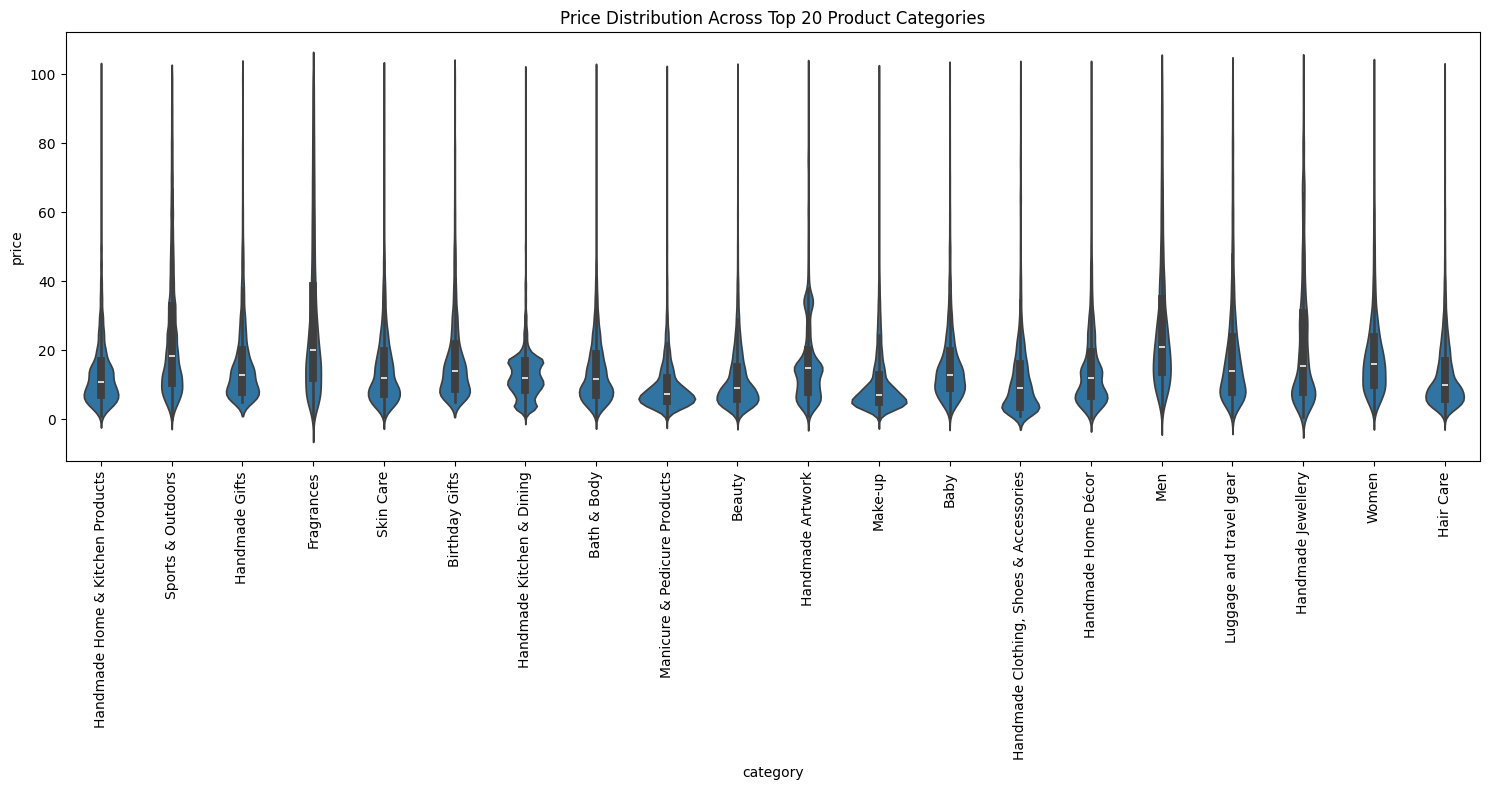

In [24]:
# Plot
plt.figure(figsize=(15, 8))
sns.violinplot(
    data=df_top20,
    x='category',
    y='price'
)

plt.xticks(rotation=90)
plt.title('Price Distribution Across Top 20 Product Categories')
plt.tight_layout()
plt.show()

In [25]:
median_prices = (
    df_top20.groupby('category')['price']
            .median()
            .sort_values(ascending=False)
)

print(median_prices)

category
Men                                       20.990
Fragrances                                20.000
Sports & Outdoors                         18.320
Women                                     15.990
Handmade Jewellery                        15.600
Handmade Artwork                          14.990
Luggage and travel gear                   13.990
Birthday Gifts                            13.990
Baby                                      12.990
Handmade Gifts                            12.990
Handmade Kitchen & Dining                 12.000
Skin Care                                 12.000
Handmade Home Décor                       11.990
Bath & Body                               11.635
Handmade Home & Kitchen Products          10.990
Hair Care                                  9.970
Beauty                                     8.990
Handmade Clothing, Shoes & Accessories     8.990
Manicure & Pedicure Products               7.500
Make-up                                    7.000
Name: price

## 2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.


In [31]:
# Top 10 categories based on number of products
top10_categories = df_amazon_no_outliers['category'].value_counts().head(10).index

In [32]:
# Filter the DataFrame
df_top10 = df_amazon_no_outliers[df_amazon_no_outliers['category'].isin(top10_categories)]

/var/folders/r0/427vxwt10rlfm84bp1jl7rs00000gn/T/ipykernel_31117/4149064716.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


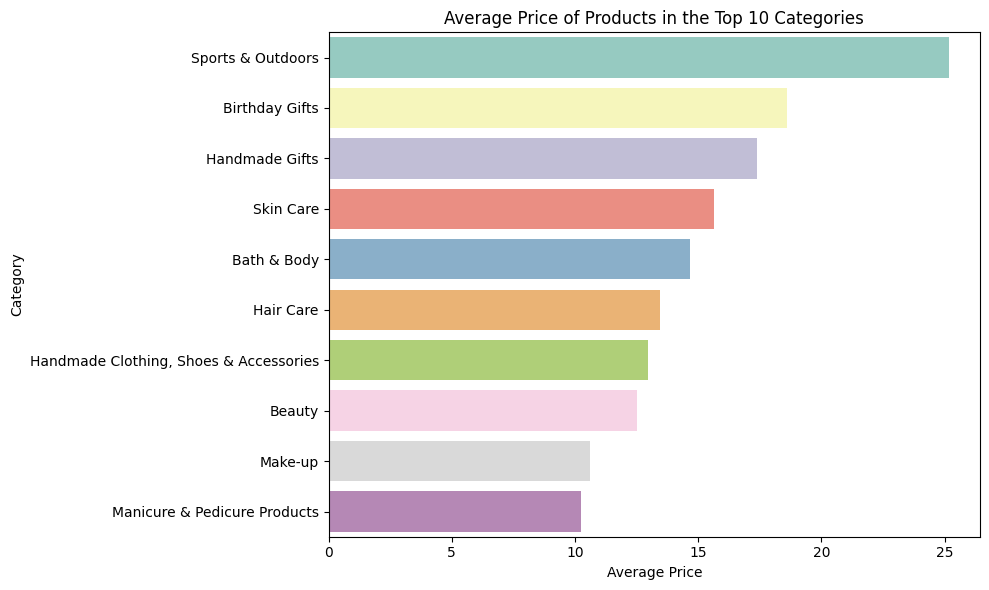

In [28]:
# Compute average price per category
avg_price = (
    df_top10.groupby('category')['price']
            .mean()
            .sort_values(ascending=False)
)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    x=avg_price.values,
    y=avg_price.index,
    palette="Set3"
)

plt.title("Average Price of Products in the Top 10 Categories")
plt.xlabel("Average Price")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## 3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [37]:
# Get the 10 most common categories
top10_categories = (
    df_amazon_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

In [38]:

# Filter the dataframe
df_top10 = df_amazon_no_outliers[
    df_amazon_no_outliers['category'].isin(top10_categories)
]

/var/folders/r0/427vxwt10rlfm84bp1jl7rs00000gn/T/ipykernel_31117/243204557.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


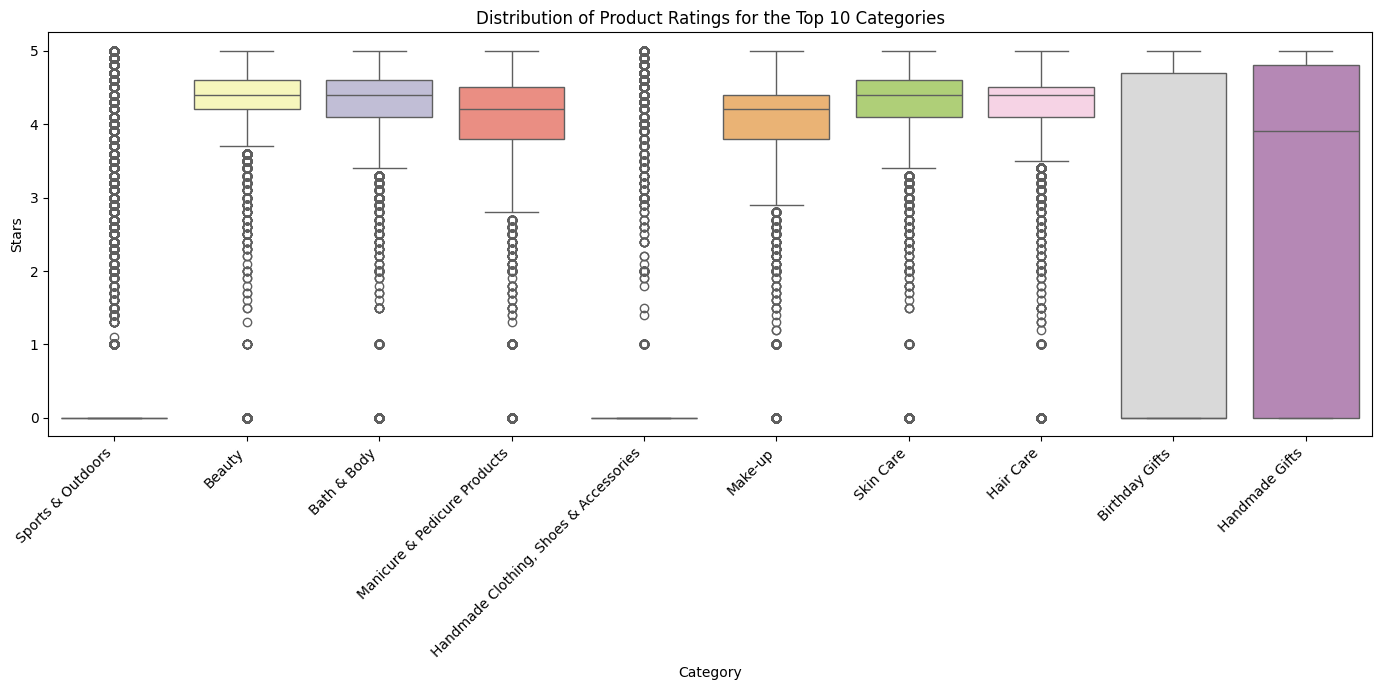

In [40]:
# Plot
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df_top10,
    x='category',
    y='stars',
    order=top10_categories,
    palette='Set3'
)

plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Product Ratings for the Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Stars')
plt.tight_layout()
plt.show()

# Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.


## 1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	

In [41]:
correlation = df_amazon[['price', 'stars']].corr()

print(correlation)

          price     stars
price  1.000000 -0.124907
stars -0.124907  1.000000


## 2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

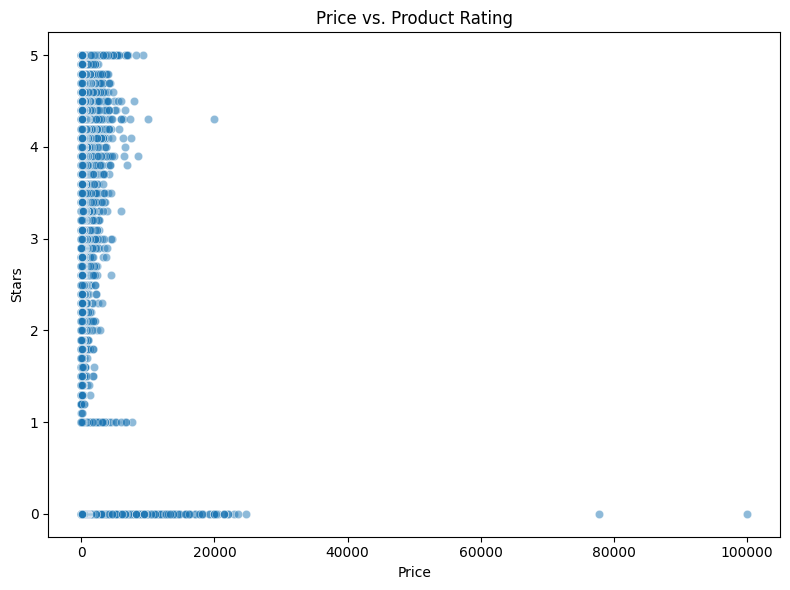

In [44]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_amazon, x='price', y='stars', alpha=0.5)

plt.title('Price vs. Product Rating')
plt.xlabel('Price')
plt.ylabel('Stars')
plt.tight_layout()
plt.show()

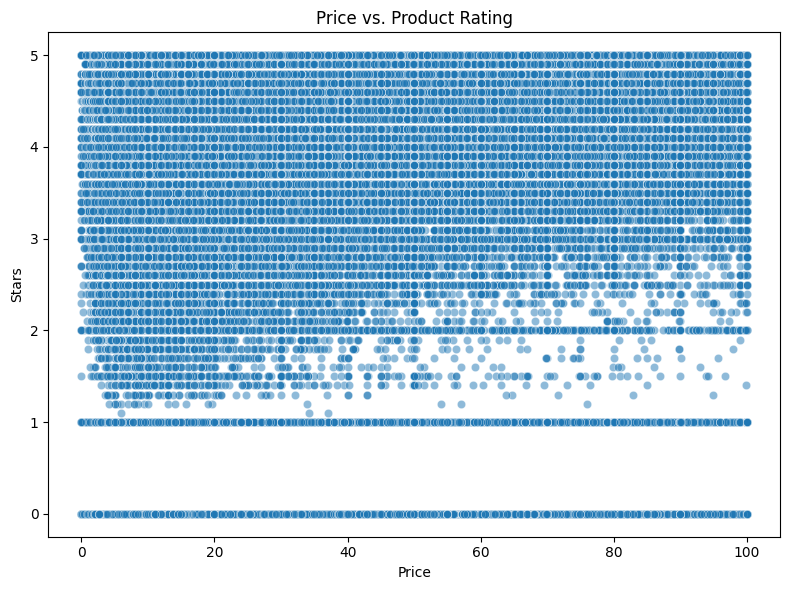

In [43]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_amazon_no_outliers, x='price', y='stars', alpha=0.5)

plt.title('Price vs. Product Rating')
plt.xlabel('Price')
plt.ylabel('Stars')
plt.tight_layout()
plt.show()

In [45]:
# Select only numerical columns
numerical_df = df_amazon_no_outliers.select_dtypes(include='number')

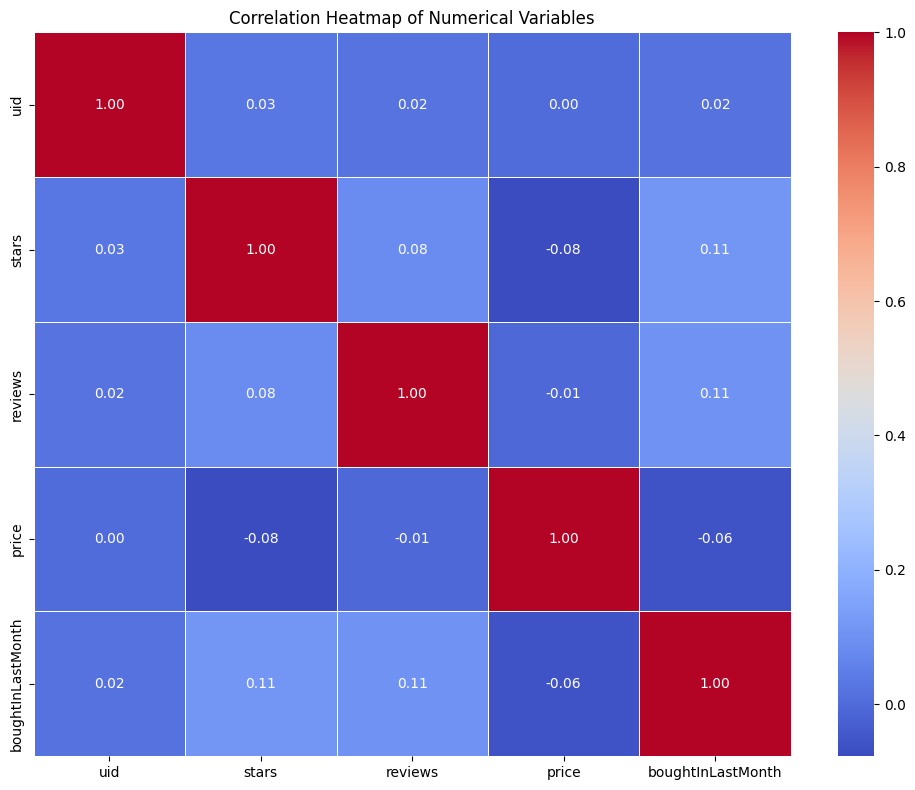

In [46]:
# Calculate correlation matrix
corr_matrix = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

In [ ]:
# Calculate correlation matrix
corr_matrix = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()